In this notebook, we generate the variance evaporation timeseries, used in Eq 14 of the paper

In [1]:
import torch
import gpytorch
import matplotlib.pyplot as plt
from gpytorch.models import ApproximateGP
from gpytorch.likelihoods import GaussianLikelihood
from gpytorch.variational import CholeskyVariationalDistribution
from torch.utils.data import DataLoader, TensorDataset
import os
import glob
import rioxarray
import numpy as np
import pandas as pd
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

### Setup Device

In [2]:
#device = torch.device("mps" if torch.backends.mps.is_available() else "cpu") # turned off bcz pytorch doesnt support mps
device = torch.device("cpu")
print(f"Using device: {device}")

Using device: cpu


### Load data

In [3]:
alexi_file = '../data/et/alexi/alexi_2003.03.01.tif'
cmrset_file = '../data/et/cmrset/cmrset_2003.03.01.tif'
sebal_file = '../data/et/sebal/sebal_2003.03.01.tif'
ssebop_file = '../data/et/ssebop/ssebop_2003.03.01.tif'
wapor_file = '../data/et/wapor/WaPOR_ETa_2003.03.01.tif'

### Read Coords and data

In [4]:
with rioxarray.open_rasterio(alexi_file) as rds:
    x_coords = rds.x.values.astype(np.float32)
    y_coords = rds.y.values.astype(np.float32)
    alexi_data = rds.squeeze().values.astype(np.float32)

with rioxarray.open_rasterio(cmrset_file) as rds:
    cmrset_data = rds.squeeze().values
with rioxarray.open_rasterio(sebal_file) as rds:
    x_coords = rds.x.values.astype(np.float32)
    y_coords = rds.y.values.astype(np.float32)
    sebal_data = rds.squeeze().values.astype(np.float32)
with rioxarray.open_rasterio(ssebop_file) as rds:
    ssebop_data = rds.squeeze().values
with rioxarray.open_rasterio(wapor_file) as rds:
    wapor_data = rds.squeeze().values

In [5]:
wapor_data.shape

(486, 244)

### Visualize all data

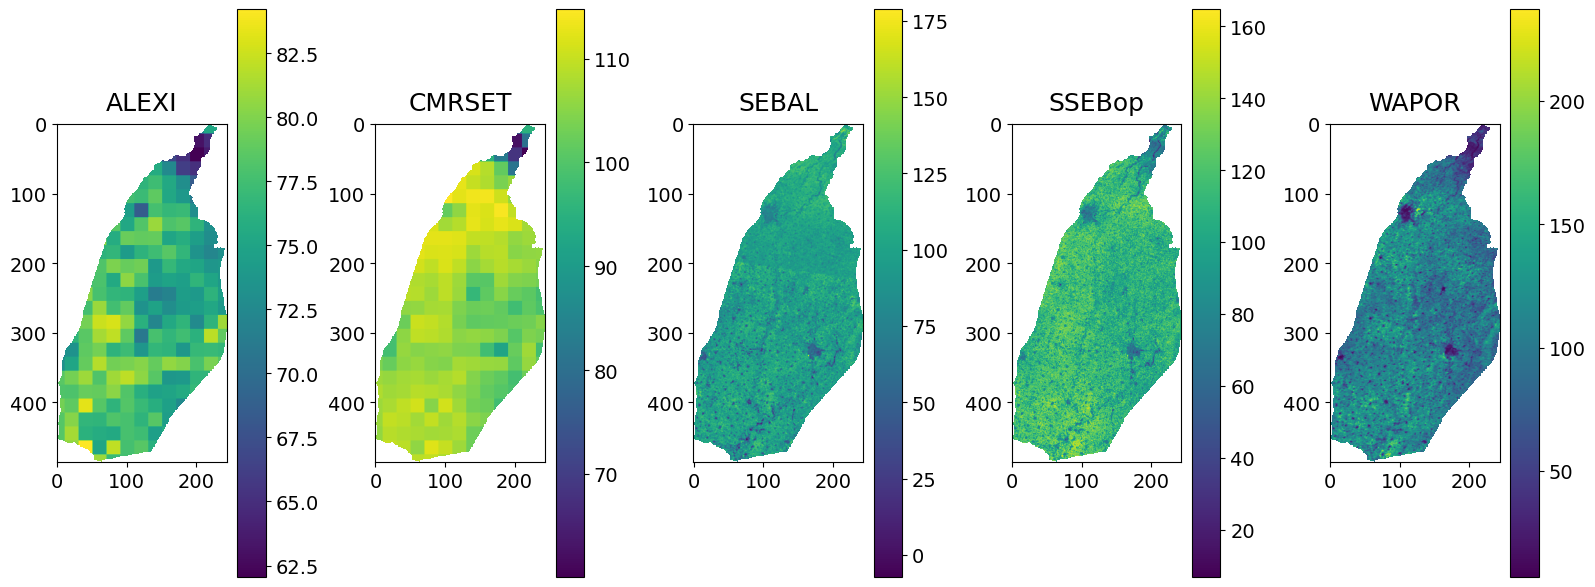

In [6]:
# Plot all products
plt.figure(figsize=(16, 6))

plt.subplot(1, 5, 1)
plt.imshow(alexi_data)
plt.title('ALEXI', fontsize=18, pad=10)
plt.colorbar().ax.tick_params(labelsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.subplot(1, 5, 2)
plt.imshow(cmrset_data)
plt.title('CMRSET', fontsize=18, pad=10)
plt.colorbar().ax.tick_params(labelsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.subplot(1, 5, 3)
plt.imshow(sebal_data)
plt.title('SEBAL', fontsize=18, pad=10)
plt.colorbar().ax.tick_params(labelsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.subplot(1, 5, 4)
plt.imshow(ssebop_data)
plt.title('SSEBop', fontsize=18, pad=10)
plt.colorbar().ax.tick_params(labelsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.subplot(1, 5, 5)
plt.imshow(wapor_data)
plt.title('WAPOR', fontsize=18, pad=10)
plt.colorbar().ax.tick_params(labelsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()
plt.show()

### Prepare the training data sets

- train_x= will be the input feature ; input spatial locations (coords)
- train_y= will be the output ; which are also called the targets or observations (et in this case)

In [7]:
LON, LAT = np.meshgrid(x_coords, y_coords)
spatial_coords = np.stack([LON.flatten(), LAT.flatten()], axis=1)

train_x = []
train_y = []

for data in [sebal_data, ssebop_data, wapor_data,alexi_data, cmrset_data,]: 
    valid_mask = ~np.isnan(data.flatten())
    if np.any(valid_mask):
        train_x.append(spatial_coords[valid_mask])
        train_y.append(data.flatten()[valid_mask])

train_x = np.vstack(train_x)
train_y = np.concatenate(train_y)

### Convert to tensors and move to device

In [8]:
train_x = torch.tensor(train_x, dtype=torch.float32).to(device)
train_y = torch.tensor(train_y, dtype=torch.float32).to(device)

In [9]:
train_x.shape  # locations are repeated to match the data (as we have 5 products)

torch.Size([355295, 2])

In [10]:
train_y.shape

torch.Size([355295])

### Normalize the train_y

- we nomalize for numarical stability when dealing with large numbers
- & initial GP parameters are designed to work with normalized data
- & it provides faster convergence
- matches assumption on normal distribution

In [11]:
y_mean = train_y.mean()
y_std = train_y.std()
train_y = (train_y - y_mean) / y_std

### Generate inducing points

In [12]:
def generate_inducing_points(n_points_per_dim, x_coords, y_coords, alexi_data):
    valid_mask = ~np.isnan(alexi_data)  
    y_idx, x_idx = np.where(valid_mask)
    x_min, x_max = x_coords[x_idx.min()], x_coords[x_idx.max()]
    y_min, y_max = y_coords[y_idx.min()], y_coords[y_idx.max()]
    # create grid
    lon_grid = np.linspace(x_min, x_max, n_points_per_dim, dtype=np.float32)
    lat_grid = np.linspace(y_min, y_max, n_points_per_dim, dtype=np.float32)
    LON, LAT = np.meshgrid(lon_grid, lat_grid)
    # use interpolation to find valid pts
    from scipy.interpolate import RegularGridInterpolator
    mask_interp = RegularGridInterpolator(
        (y_coords, x_coords), 
        valid_mask.astype(float),
        method='nearest', 
        bounds_error=False, 
        fill_value=0 #values outside the basin boundaries are given 0 values
    )
    
    points = np.stack([LAT.ravel(), LON.ravel()], axis=1)
    is_valid = mask_interp(points) > 0.5#only select the valid pts as inducing pts
    valid_points = points[is_valid]
    return torch.tensor(np.column_stack([valid_points[:, 1], valid_points[:, 0]]), dtype=torch.float32).to(device)


- visualize the inducing pts

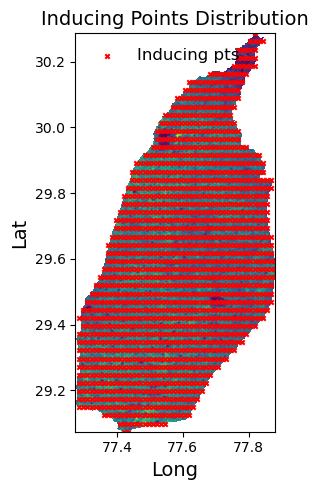

# inducing pts: 1449


In [13]:
inducing_points = generate_inducing_points(50, x_coords, y_coords, alexi_data)  
plt.figure(figsize=(4, 5))
plt.scatter(inducing_points.cpu()[:, 0], inducing_points.cpu()[:, 1], 
            c='red', marker='x', s=10, label='Inducing pts')
plt.imshow(wapor_data, cmap='viridis', 
          extent=[x_coords.min(), x_coords.max(), y_coords.min(), y_coords.max()])
plt.xlabel('Long', fontsize=14)
plt.ylabel('Lat', fontsize=14)
plt.legend(fontsize=12,frameon=False)
plt.title('Inducing Points Distribution', fontsize=14)
plt.tight_layout()
plt.show()

print(f'# inducing pts: {len(inducing_points)}')

### Define Sparse Matern GP model

In [14]:
class SparseMaternGP(gpytorch.models.ApproximateGP):
    def __init__(self, inducing_points, nu=1.5):
        inducing_points = inducing_points.to(torch.float32)
        variational_distribution = gpytorch.variational.CholeskyVariationalDistribution(inducing_points.size(0))
        variational_strategy = gpytorch.variational.VariationalStrategy(
            self, inducing_points, variational_distribution, learn_inducing_locations=True,jitter_val=1e-3) #add noise to the diagonal

        super(SparseMaternGP, self).__init__(variational_strategy)
        self.mean_module = gpytorch.means.ConstantMean()
        self.base_kernel = gpytorch.kernels.MaternKernel(nu=nu)
        self.covar_module = gpytorch.kernels.ScaleKernel(self.base_kernel)
        self.covar_module.outputscale = 1.0 #fix the outputscale to 1
        self.covar_module.requires_grad_(False) #make sure that this param is not updated in the backward pass;during optimization

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

### Create DataLoaders

In [15]:
n_points_per_dim = 20  
lengthscale = 0.45      
lr = 0.0008              
batch_size = 512     
num_epochs = 200

full_dataset = TensorDataset(train_x, train_y)
full_dataloader = DataLoader(full_dataset, batch_size=batch_size, shuffle=True)

- initialize the model with parameters

In [16]:
inducing_points = generate_inducing_points(n_points_per_dim, x_coords, y_coords, alexi_data)
model = SparseMaternGP(inducing_points, nu=1.5).to(device)
model.base_kernel.lengthscale = torch.tensor(lengthscale).to(device)
likelihood = GaussianLikelihood().to(device)
likelihood.noise = torch.tensor(0.0001).to(device)

- perform training with the full dataset

In [17]:
optimizer = torch.optim.Adam([
    {'params': model.parameters()},
    {'params': likelihood.parameters()}
], lr=lr)

mll = gpytorch.mlls.VariationalELBO(likelihood, model, num_data=len(train_y))

losses = []

model.train()
likelihood.train()

for epoch in range(num_epochs):
    epoch_loss = 0
    for batch_x, batch_y in full_dataloader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        output = model(batch_x)
        loss = -mll(output, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    
    avg_loss = epoch_loss / len(full_dataloader)
    losses.append(avg_loss)
    if epoch % 10 == 0:
        print(f'Epoch {epoch}: Average Loss = {avg_loss:.4f}')

Epoch 0: Average Loss = 5215.6456
Epoch 10: Average Loss = 4599.8146
Epoch 20: Average Loss = 4566.1595
Epoch 30: Average Loss = 4545.1713
Epoch 40: Average Loss = 4531.8603
Epoch 50: Average Loss = 4520.3093
Epoch 60: Average Loss = 4511.1659
Epoch 70: Average Loss = 4504.0047
Epoch 80: Average Loss = 4498.4665
Epoch 90: Average Loss = 4494.7288
Epoch 100: Average Loss = 4491.0557
Epoch 110: Average Loss = 4487.2193
Epoch 120: Average Loss = 4485.5087
Epoch 130: Average Loss = 4482.1968
Epoch 140: Average Loss = 4480.2275
Epoch 150: Average Loss = 4477.8799
Epoch 160: Average Loss = 4476.3921
Epoch 170: Average Loss = 4475.0768
Epoch 180: Average Loss = 4473.5455
Epoch 190: Average Loss = 4471.2246


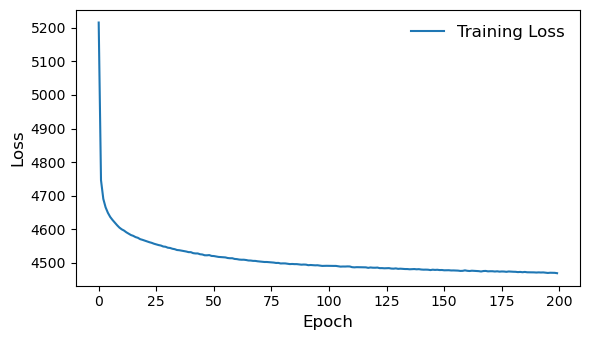

In [18]:
# Plot training loss for full dataset training
plt.figure(figsize=(6, 3.5))
plt.plot(losses, label='Training Loss')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12, frameon=False)
plt.tight_layout()
plt.show()


- save the trained model

In [19]:
def save_model(model, likelihood, y_mean, y_std, inducing_points, save_path='../variationalgp_MaternEnsemblesEvapV.pt'):
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    torch.save({ #to save model state
        'model_state_dict': model.state_dict(),
        'likelihood_state_dict': likelihood.state_dict(),
        'y_mean': y_mean,
        'y_std': y_std,
        'inducing_points': inducing_points,
        'lengthscale': model.covar_module.base_kernel.lengthscale.item(),
        'outputscale': model.covar_module.outputscale.item(),
        'noise': likelihood.noise.item(),
    }, save_path)

In [20]:
save_model(model, likelihood, y_mean, y_std, inducing_points)

- load the model

In [21]:
def load_model(load_path='../variationalgp_MaternEnsemblesEvapV.pt', device=None):
    import torch
    import gpytorch
    from gpytorch.models import ApproximateGP
    from gpytorch.likelihoods import GaussianLikelihood
    from gpytorch.variational import CholeskyVariationalDistribution
    
    if device is None:
        device = torch.device("cpu")
    
    checkpoint = torch.load(load_path, map_location=device)
    inducing_points = checkpoint['inducing_points'].to(device)

    class SparseMaternGP(gpytorch.models.ApproximateGP):
        def __init__(self, inducing_points, nu=1.5):
            inducing_points = inducing_points.to(torch.float32)
            variational_distribution = gpytorch.variational.CholeskyVariationalDistribution(inducing_points.size(0))
            variational_strategy = gpytorch.variational.VariationalStrategy(
                self, inducing_points, variational_distribution, learn_inducing_locations=True, jitter_val=1e-3)

            super(SparseMaternGP, self).__init__(variational_strategy)
            self.mean_module = gpytorch.means.ConstantMean()
            self.base_kernel = gpytorch.kernels.MaternKernel(nu=nu)
            self.covar_module = gpytorch.kernels.ScaleKernel(self.base_kernel)
            self.covar_module.outputscale = 1.0
            self.covar_module.requires_grad_(False)

        def forward(self, x):
            mean_x = self.mean_module(x)
            covar_x = self.covar_module(x)
            return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

    model = SparseMaternGP(inducing_points, nu=1.5).to(device)
    likelihood = GaussianLikelihood().to(device)
    
    #load saved params
    model.load_state_dict(checkpoint['model_state_dict'])
    likelihood.load_state_dict(checkpoint['likelihood_state_dict'])
    model.base_kernel.lengthscale = torch.tensor(checkpoint['lengthscale']).to(device)
    model.covar_module.outputscale = torch.tensor(checkpoint['outputscale']).to(device)
    likelihood.noise = torch.tensor(checkpoint['noise']).to(device)
    model.eval()
    likelihood.eval()
    
    return model, likelihood, checkpoint['y_mean'], checkpoint['y_std']

In [22]:
model, likelihood, y_mean, y_std = load_model(load_path='../variationalgp_MaternEnsemblesEvapV.pt', device=device)

In [23]:
print(f"final lengthscale: {model.covar_module.base_kernel.lengthscale.item():.3f}")
print(f"final  outputscale: {model.covar_module.outputscale.item():.3f}")
print(f"final  likelihood noise: {likelihood.noise.item():.3f}")

final lengthscale: 0.450
final  outputscale: 1.000
final  likelihood noise: 0.000


In [24]:
fast_comp_settings = gpytorch.settings.fast_pred_var()
def compute_R(model, spatial_coords, valid_mask, batch_size=500):
    model.eval()
    valid_coords = torch.tensor(spatial_coords[valid_mask], dtype=torch.float32).to(device)
    n_valid = len(valid_coords)
    print(f"matrix size: {n_valid}x{n_valid}")
    R = torch.zeros(n_valid, n_valid, dtype=torch.float32).to(device)
    with torch.no_grad(), fast_comp_settings:
        valid_loader = DataLoader(valid_coords, batch_size=batch_size, shuffle=False)
        for i, batch_x1 in enumerate(tqdm(valid_loader, desc="computing R")):
            start_i = i * batch_size
            end_i = start_i + batch_x1.size(0)
            for j, batch_x2 in enumerate(valid_loader):
                start_j = j * batch_size
                end_j = start_j + batch_x2.size(0)
                K = model.covar_module(batch_x1, batch_x2).evaluate()
                R[start_i:end_i, start_j:end_j] = K
    return R

In [25]:
batch_size = 500  
R_tensor = compute_R(model, spatial_coords, valid_mask, batch_size=batch_size)
R = R_tensor.cpu().numpy()
print(f"R shape: {R.shape}, size: {R.size}")#,

matrix size: 71059x71059


computing R: 100%|████████████████████████████| 143/143 [00:33<00:00,  4.31it/s]

R shape: (71059, 71059), size: 5049381481


In [26]:
#print(f"avg: {np.mean(R):.2f}, min: {np.min(R):.2f}, max: {np.max(R):.2f}")

In [27]:
# Create heatmap of a subset of R
#plt.figure(figsize=(8, 8))
#plt.imshow(R[:10000, :10000], cmap='viridis')
#plt.colorbar(label='Correlation')
#plt.title('Correlation Matrix Heatmap (Subset)')
#plt.show()

- read data from rasters

In [ ]:
emax_folder = '../data/Emax'
emin_folder = '../data/Emin'

emax_files = sorted(glob.glob(os.path.join(emax_folder, '*.tif')))
emin_files = sorted(glob.glob(os.path.join(emin_folder, '*.tif')))

common_dates = [os.path.basename(f)[-14:-4] for f in emax_files]

In [ ]:
s_means = {}
v_means = {}

for date_str in tqdm(common_dates):
    emax_file = os.path.join(emax_folder, f'Emax_{date_str}.tif')
    emin_file = os.path.join(emin_folder, f'Emin_{date_str}.tif')
    
    with rioxarray.open_rasterio(emax_file) as rds:
        emax_data = rds.squeeze().values.astype(np.float32)
    with rioxarray.open_rasterio(emin_file) as rds:
        emin_data = rds.squeeze().values.astype(np.float32)
    
    emax_vals = emax_data.flatten()[valid_mask]
    emin_vals = emin_data.flatten()[valid_mask]
    
    # diagonal S (0.5 * |Emax - Emin|)
    s_diag = 0.25 * np.abs(emax_vals - emin_vals)
    s_means[date_str] = np.mean(s_diag)
    
    # Efficient computation of the mean of V = S @ R @ S
    # For a matrix product S @ R @ S, where S is diagonal,
    # the mean can be computed as: mean(S @ R @ S) = (s @ R @ s) / n²
    # where s is the vector of diagonal elements of S and n is the dimension
    
    # thus we ue here the vector form instead of the diagonal matrix
    s_vector = s_diag
  
    Rs = R @ s_vector  
    sRs = s_vector @ Rs  #cov

    n = len(s_vector)
    v_mean = sRs / (n * n)
    v_means[date_str] = v_mean
    
    print(f"Date: {date_str}, S mean: {s_means[date_str]:.2f}, V mean: {v_mean:.2f}")

# Save mean values
pd.DataFrame.from_dict(s_means, orient='index', columns=['Smean']).to_csv('../output/SEmean.csv')
pd.DataFrame.from_dict(v_means, orient='index', columns=['Vmean']).to_csv('../output/VEmean.csv')